In [35]:
#https://www.kaggle.com/competitions/eel-891-2026-02-trabalho-2

In [102]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [103]:
import pandas as pd

df = pd.read_csv('conjunto_de_treinamento.csv')
df.head()

,Id,tipo,bairro,tipo_vendedor,quartos,suites,vagas,area_util,area_extra,diferenciais,...,estacionamento,piscina,playground,quadra,s_festas,s_jogos,s_ginastica,sauna,vista_mar,preco
0,2000,Casa,Imbiribeira,Imobiliaria,3,3,5,223,167,piscina e copa,...,0,1,0,0,0,0,0,0,0,1000000.0
1,2001,Apartamento,Casa Amarela,Imobiliaria,4,4,2,157,0,piscina e churrasqueira,...,0,1,0,0,0,0,0,0,0,680000.0
2,2002,Apartamento,Encruzilhada,Imobiliaria,3,1,0,53,0,nenhum,...,0,0,0,0,0,0,0,0,0,450000.0
3,2003,Apartamento,Boa Viagem,Imobiliaria,4,3,2,149,0,piscina e churrasqueira,...,0,1,0,0,0,0,0,0,0,1080000.0
4,2004,Apartamento,Rosarinho,Imobiliaria,2,1,1,54,0,piscina e churrasqueira,...,0,1,0,0,0,0,0,0,0,350000.0


In [104]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4683 entries, 0 to 4682
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Id              4683 non-null   int64  
 1   tipo            4683 non-null   str    
 2   bairro          4683 non-null   str    
 3   tipo_vendedor   4683 non-null   str    
 4   quartos         4683 non-null   int64  
 5   suites          4683 non-null   int64  
 6   vagas           4683 non-null   int64  
 7   area_util       4683 non-null   int64  
 8   area_extra      4683 non-null   int64  
 9   diferenciais    4683 non-null   str    
 10  churrasqueira   4683 non-null   int64  
 11  estacionamento  4683 non-null   int64  
 12  piscina         4683 non-null   int64  
 13  playground      4683 non-null   int64  
 14  quadra          4683 non-null   int64  
 15  s_festas        4683 non-null   int64  
 16  s_jogos         4683 non-null   int64  
 17  s_ginastica     4683 non-null   int64  
 18 

In [105]:
df['churrasqueira'].head()

0    0
1    1
2    0
3    1
4    1
Name: churrasqueira, dtype: int64

In [106]:
print(f"Número de linhas: {df.shape[0]}\nNúmero de colunas: {df.shape[1]}")

Número de linhas: 4683
Número de colunas: 21


In [107]:
print(f"Os valores da coluna 'tipo' são:\n{df["tipo"].unique()}")

Os valores da coluna 'tipo' são:
<StringArray>
['Casa', 'Apartamento', 'Quitinete', 'Loft']
Length: 4, dtype: str


In [108]:
print(f"Os valores da coluna 'bairro' são:\n{df["bairro"].unique()}")

Os valores da coluna 'bairro' são:
<StringArray>
[      'Imbiribeira',      'Casa Amarela',      'Encruzilhada',
        'Boa Viagem',         'Rosarinho',         'Boa Vista',
        'Espinheiro',       'Tamarineira',            'Gracas',
          'Madalena',        'Parnamirim',            'S Jose',
           'Setubal',            'Arruda',              'Pina',
         'Beira Rio',           'Caxanga',        'Casa Forte',
             'Prado',          'Iputinga',      'Campo Grande',
       'Dois Irmaos',           'Torreao',    'Ilha do Retiro',
            'Areias',            'Varzea',          'Cordeiro',
             'Torre',           'Santana',             'Barro',
    'Poco da Panela',             'Ipsep',           'Aflitos',
              'Poco',          'Apipucos',             'Derby',
 'Cid Universitaria',             'Bongi',          'Jaqueira',
         'Sto Amaro',           'Tejipio',            'Recife',
          'Monteiro',         'Macaxeira',            '

In [109]:
print(f"Os valores da coluna 'tipo_vendedor' são:\n{df["tipo_vendedor"].unique()}")

Os valores da coluna 'tipo_vendedor' são:
<StringArray>
['Imobiliaria', 'Pessoa Fisica']
Length: 2, dtype: str


In [110]:
print(f"Os valores da coluna 'diferenciais' são:\n{df["diferenciais"].unique()}")

Os valores da coluna 'diferenciais' são:
<StringArray>
[                               'piscina e copa',
                       'piscina e churrasqueira',
                                        'nenhum',
                                    'playground',
                          'piscina e playground',
                            'sauna e playground',
                               'piscina e sauna',
                'piscina e quadra poliesportiva',
                               'salao de festas',
                 'campo de futebol e playground',
           'piscina e estacionamento visitantes',
                        'copa e salao de festas',
                     'esquina e salao de festas',
                     'piscina e salao de festas',
                'playground e sala de ginastica',
                             'copa e playground',
        'estacionamento visitantes e playground',
                  'playground e salao de festas',
                    'churrasqueira e playgrou

In [111]:
df.describe()

,Id,quartos,suites,vagas,area_util,area_extra,churrasqueira,estacionamento,piscina,playground,quadra,s_festas,s_jogos,s_ginastica,sauna,vista_mar,preco
count,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4.683000e+03
mean,4341.000000,3.043562,1.434337,1.708093,124.158018,13.293188,0.316891,0.030750,0.555627,0.157378,0.039078,0.138159,0.006833,0.013666,0.096306,0.027333,9.277053e+05
std,1352.009985,0.873590,1.102457,1.210975,107.365110,266.803756,0.465314,0.172657,0.496949,0.364195,0.193800,0.345104,0.082389,0.116114,0.295042,0.163069,1.050607e+07
min,2000.000000,1.000000,0.000000,0.000000,21.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.500000e+02
25%,3170.500000,3.000000,1.000000,1.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.550000e+05
50%,4341.000000,3.000000,1.000000,2.000000,96.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.150000e+05
75%,5511.500000,4.000000,2.000000,2.000000,149.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.300000e+05
max,6682.000000,9.000000,6.000000,30.000000,2045.000000,17450.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,6.300000e+08


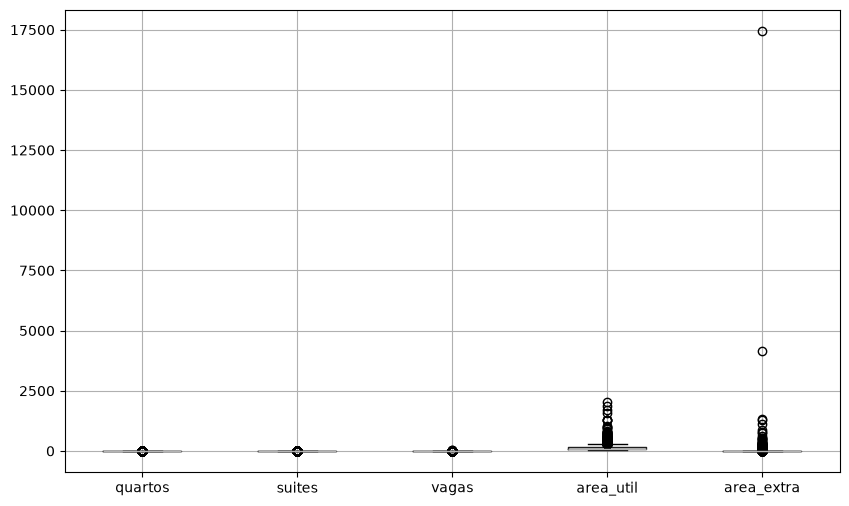

In [112]:
plt.figure(figsize=(10,6))
df.boxplot(column=["quartos","suites","vagas","area_util","area_extra"])
plt.show()
#devo remover esses outliers?

In [113]:
processed_df = pd.read_csv('conjunto_de_treinamento_onehot.csv')

In [114]:
processed_df.head()

,Id,quartos,suites,vagas,area_util,area_extra,tipo_Apartamento,tipo_Casa,tipo_Loft,tipo_Quitinete,...,diferenciais_piscina,diferenciais_playground,diferenciais_quadra_de_squash,diferenciais_quadra_poliesportiva,diferenciais_sala_de_ginastica,diferenciais_salao_de_festas,diferenciais_salao_de_jogos,diferenciais_sauna,diferenciais_vestiario,preco
0,2000,3,3,5,223,167,0,1,0,0,...,1,0,0,0,0,0,0,0,0,1000000.0
1,2001,4,4,2,157,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,680000.0
2,2002,3,1,0,53,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,450000.0
3,2003,4,3,2,149,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,1080000.0
4,2004,2,1,1,54,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,350000.0


In [115]:
print(f"Número de linhas: {processed_df.shape[0]}\nNúmero de colunas: {processed_df.shape[1]}")

Número de linhas: 4683
Número de colunas: 97


In [116]:
print(f"Número de linhas: {df.shape[0]}\nNúmero de colunas: {df.shape[1]}")

Número de linhas: 4683
Número de colunas: 21


In [117]:
processed_df.describe()

,Id,quartos,suites,vagas,area_util,area_extra,tipo_Apartamento,tipo_Casa,tipo_Loft,tipo_Quitinete,...,diferenciais_piscina,diferenciais_playground,diferenciais_quadra_de_squash,diferenciais_quadra_poliesportiva,diferenciais_sala_de_ginastica,diferenciais_salao_de_festas,diferenciais_salao_de_jogos,diferenciais_sauna,diferenciais_vestiario,preco
count,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,...,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4.683000e+03
mean,4341.000000,3.043562,1.434337,1.708093,124.158018,13.293188,0.961136,0.037796,0.000641,0.000427,...,0.555627,0.157378,0.000214,0.016015,0.013666,0.138159,0.006833,0.096306,0.000854,9.277053e+05
std,1352.009985,0.873590,1.102457,1.210975,107.365110,266.803756,0.193291,0.190724,0.025305,0.020664,...,0.496949,0.364195,0.014613,0.125548,0.116114,0.345104,0.082389,0.295042,0.029217,1.050607e+07
min,2000.000000,1.000000,0.000000,0.000000,21.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.500000e+02
25%,3170.500000,3.000000,1.000000,1.000000,68.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.550000e+05
50%,4341.000000,3.000000,1.000000,2.000000,96.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.150000e+05
75%,5511.500000,4.000000,2.000000,2.000000,149.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.300000e+05
max,6682.000000,9.000000,6.000000,30.000000,2045.000000,17450.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,6.300000e+08


In [118]:
processed_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4683 entries, 0 to 4682
Data columns (total 97 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Id                                      4683 non-null   int64  
 1   quartos                                 4683 non-null   int64  
 2   suites                                  4683 non-null   int64  
 3   vagas                                   4683 non-null   int64  
 4   area_util                               4683 non-null   int64  
 5   area_extra                              4683 non-null   int64  
 6   tipo_Apartamento                        4683 non-null   int64  
 7   tipo_Casa                               4683 non-null   int64  
 8   tipo_Loft                               4683 non-null   int64  
 9   tipo_Quitinete                          4683 non-null   int64  
 10  bairro_Aflitos                          4683 non-null   int64  
 11  ba

In [119]:
processed_df = processed_df.drop('Id', axis = 1)

In [123]:
colunas_numericas = ['quartos', 'suites', 'vagas', 'area_util', 'area_extra']

In [127]:
scaler = StandardScaler()
processed_df[colunas_numericas] = scaler.fit_transform(processed_df[colunas_numericas])

In [128]:
processed_df.describe()

,quartos,suites,vagas,area_util,area_extra,tipo_Apartamento,tipo_Casa,tipo_Loft,tipo_Quitinete,bairro_Aflitos,...,diferenciais_piscina,diferenciais_playground,diferenciais_quadra_de_squash,diferenciais_quadra_poliesportiva,diferenciais_sala_de_ginastica,diferenciais_salao_de_festas,diferenciais_salao_de_jogos,diferenciais_sauna,diferenciais_vestiario,preco
count,4.683000e+03,4.683000e+03,4.683000e+03,4.683000e+03,4.683000e+03,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,...,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4683.000000,4.683000e+03
mean,-3.944931e-17,-7.586405e-18,-4.551843e-18,-8.724366e-18,4.551843e-18,0.961136,0.037796,0.000641,0.000427,0.016442,...,0.555627,0.157378,0.000214,0.016015,0.013666,0.138159,0.006833,0.096306,0.000854,9.277053e+05
std,1.000107e+00,1.000107e+00,1.000107e+00,1.000107e+00,1.000107e+00,0.193291,0.190724,0.025305,0.020664,0.127183,...,0.496949,0.364195,0.014613,0.125548,0.116114,0.345104,0.082389,0.295042,0.029217,1.050607e+07
min,-2.339518e+00,-1.301175e+00,-1.410662e+00,-9.609177e-01,-4.982916e-02,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.500000e+02
25%,-4.987061e-02,-3.940138e-01,-5.847924e-01,-5.231124e-01,-4.982916e-02,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.550000e+05
50%,-4.987061e-02,-3.940138e-01,2.410770e-01,-2.622921e-01,-4.982916e-02,1.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.150000e+05
75%,1.094953e+00,5.131477e-01,2.410770e-01,2.314032e-01,-4.982916e-02,1.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.300000e+05
max,6.819073e+00,4.141794e+00,2.336542e+01,1.789266e+01,6.536103e+01,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,6.300000e+08
